# 2. Import Library

In [31]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Library berhasil diimpor.")

Device: cpu
Library berhasil diimpor.


In [32]:
# Load dataset GoPay
possible_paths = [
    "review_gopay_newest_sort(2).csv",
    "review_gopay_newest_sort(1).csv",
    "review_gopay_newest_sort.csv",
    "dataset_preprocessed.csv",
    "../dataset/review_gopay_newest_sort(2).csv",
    "../dataset/dataset_preprocessed.csv"
]

from pathlib import Path
import pandas as pd

file_path = Path("../dataset_preprocessed.csv")

if not file_path.is_file():
    raise FileNotFoundError(f"File tidak ditemukan: {file_path.resolve()}")

df = pd.read_csv(file_path, low_memory=False)

if file_path is None:
    raise FileNotFoundError("File dataset tidak ditemukan.")

df = pd.read_csv(file_path, low_memory=False)

# Menggunakan kolom content
df = df.dropna(subset=["content"]).copy()
df["content"] = df["content"].astype(str).str.strip()
df = df[df["content"] != ""].drop_duplicates(subset=["content"])

print("Dataset:", file_path)
print("Jumlah data:", len(df))
print("Kolom teks: content")

display(df[["content"]].head())

Dataset: ..\dataset_preprocessed.csv
Jumlah data: 78431
Kolom teks: content


,content
0,Mantap
1,Bagus dan mudah digunakan
2,Good
3,Sangat membantu orang menengah mantap semoga s...
4,Ga ribet .. Sukaaaa


# 3. Implementasi Attention Sederhana

In [33]:
class BahdanauAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(BahdanauAttention, self).__init__()

        self.W_query = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_key = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, query, keys):
        query = query.unsqueeze(1)

        energy = torch.tanh(
            self.W_query(query) + self.W_key(keys)
        )

        scores = self.v(energy).squeeze(-1)
        weights = F.softmax(scores, dim=-1)

        context = torch.bmm(
            weights.unsqueeze(1), keys
        ).squeeze(1)

        return context, weights

# Demonstrasi menggunakan ulasan GoPay:
# Mengambil satu ulasan dari kolom content
review = df["content"].iloc[0]

import re

tokens = re.findall(r"\b\w+\b", str(review).lower())
tokens = tokens[:8]

hidden_dim = 64

attention = BahdanauAttention(hidden_dim).to(device)

query = torch.randn(1, hidden_dim).to(device)
keys = torch.randn(1, len(tokens), hidden_dim).to(device)

context, weights = attention(query, keys)

print("Ulasan GoPay:")
print(review)
print("\nToken Ulasan:")
print(tokens)
print("\nContext Vector:")
print(context)
print("\nAttention Weights:")
print(weights)
print("\nContext Shape:", context.shape)
print("Attention Weights Shape:", weights.shape)


Ulasan GoPay:
Mantap

Token Ulasan:
['mantap']

Context Vector:
tensor([[-1.3938,  0.8466, -1.7191,  0.5333, -1.1904,  0.3421, -0.3002,  1.0045,
          0.6923,  1.0485, -0.1510, -2.2977, -0.1244, -0.7996,  0.7430, -0.8086,
         -0.5073, -0.6935,  0.8880, -1.5327, -0.4972,  0.5914,  1.1191,  0.1540,
         -1.2935, -0.5709,  1.3834,  0.6252, -0.6523, -0.8380, -1.2592,  0.3141,
          0.5190,  0.5709,  1.6640,  2.1912, -0.9769, -1.8608, -0.2392,  0.5643,
          0.3393,  1.5300,  2.6910,  0.6581, -1.1971, -1.9605, -0.7572, -1.0060,
         -0.4609, -0.7703, -1.3132, -0.0510,  1.4957,  0.8451, -0.4245,  1.3252,
         -0.0467, -0.5347,  1.6594, -0.3404, -1.2555, -1.1867,  0.1320,  0.3407]],
       grad_fn=<SqueezeBackward1>)

Attention Weights:
tensor([[1.]], grad_fn=<SoftmaxBackward0>)

Context Shape: torch.Size([1, 64])
Attention Weights Shape: torch.Size([1, 1])


# 4. Implementasi Scaled Dot-Product Attention

In [34]:
class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_k):
        super(ScaledDotProductAttention, self).__init__()
        self.scale = d_k ** 0.5

    def forward(self, Q, K, V, mask=None):
        scores = torch.bmm(
            Q, K.transpose(1, 2)
        ) / self.scale

        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        weights = F.softmax(scores, dim=-1)
        output = torch.bmm(weights, V)

        return output, weights

# Demonstrasi Scaled Dot-Product Attention:
# Mengambil ulasan GoPay
review = df["content"].iloc[0]
tokens = re.findall(r"\b\w+\b", str(review).lower())
tokens = tokens[:8]

d_k = 8

attention = ScaledDotProductAttention(d_k)

Q = torch.randn(1, 3, d_k)
K = torch.randn(1, len(tokens), d_k)
V = torch.randn(1, len(tokens), d_k)

output, weights = attention(Q, K, V)

print("Ulasan GoPay:")
print(review)
print("\nToken Ulasan:")
print(tokens)
print("\nQuery Shape:", Q.shape)
print("Key Shape:", K.shape)
print("Value Shape:", V.shape)
print("\nAttention Output:")
print(output)
print("\nAttention Weights:")
print(weights)
print("\nOutput Shape:", output.shape)
print("Weights Shape:", weights.shape)

Ulasan GoPay:
Mantap

Token Ulasan:
['mantap']

Query Shape: torch.Size([1, 3, 8])
Key Shape: torch.Size([1, 1, 8])
Value Shape: torch.Size([1, 1, 8])

Attention Output:
tensor([[[-0.6413,  1.4868,  1.5816, -0.2866, -0.0051,  1.1674,  0.8576,
           1.2866],
         [-0.6413,  1.4868,  1.5816, -0.2866, -0.0051,  1.1674,  0.8576,
           1.2866],
         [-0.6413,  1.4868,  1.5816, -0.2866, -0.0051,  1.1674,  0.8576,
           1.2866]]])

Attention Weights:
tensor([[[1.],
         [1.],
         [1.]]])

Output Shape: torch.Size([1, 3, 8])
Weights Shape: torch.Size([1, 3, 1])


# 5. Visualisasi Attention Weights

Ulasan GoPay:
Mantap


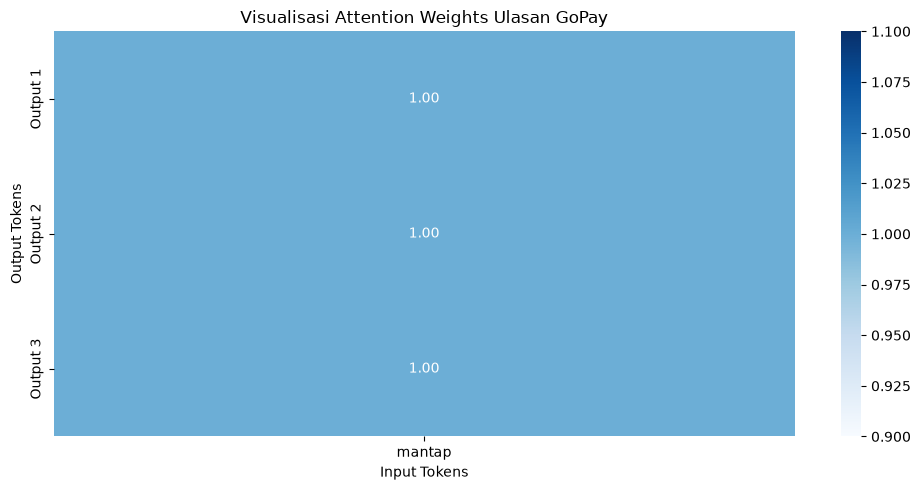

In [35]:
def visualize_attention(weights, input_tokens, output_tokens, title):
    plt.figure(figsize=(10, 5))

    sns.heatmap(
        weights,
        xticklabels=input_tokens,
        yticklabels=output_tokens,
        cmap="Blues",
        annot=True,
        fmt=".2f"
    )

    plt.title(title)
    plt.xlabel("Input Tokens")
    plt.ylabel("Output Tokens")
    plt.tight_layout()
    plt.show()

# Demonstrasi visualisasi menggunakan dataset GoPay:
review = df["content"].iloc[0]

input_tokens = re.findall(
    r"\b\w+\b", str(review).lower()
)[:8]

np.random.seed(42)

weights_demo = np.random.rand(3, len(input_tokens))
weights_demo = weights_demo / weights_demo.sum(
    axis=1, keepdims=True
)

output_tokens = ["Output 1", "Output 2", "Output 3"]

print("Ulasan GoPay:")
print(review)

visualize_attention(
    weights_demo,
    input_tokens,
    output_tokens,
    "Visualisasi Attention Weights Ulasan GoPay"
)

# 6. Demonstrasi Attention pada Contoh Sederhana

Ulasan GoPay:
Mantap

Token Ulasan:
['mantap']


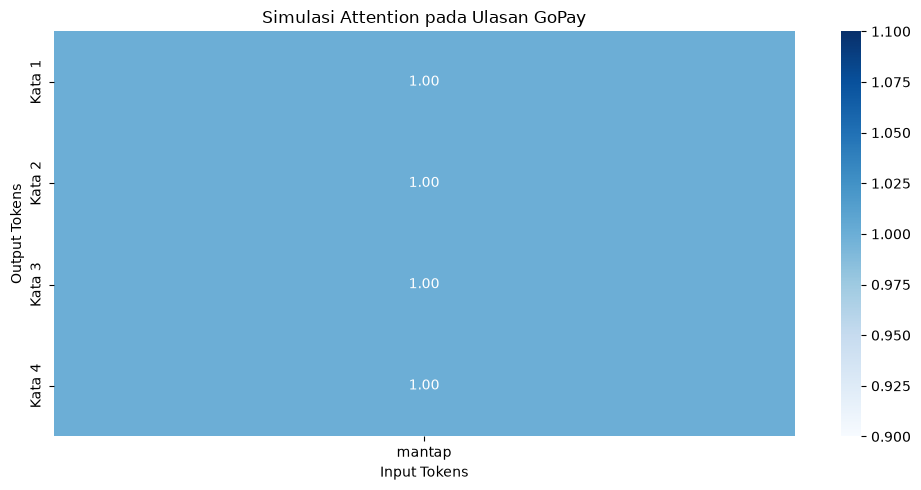

In [36]:
review = df["content"].iloc[0]

input_tokens = re.findall(
    r"\b\w+\b", str(review).lower()
)[:12]

np.random.seed(42)

attention_weights = np.random.rand(
    4, len(input_tokens)
)

attention_weights = attention_weights / attention_weights.sum(
    axis=1, keepdims=True
)

output_tokens = [
    "Kata 1",
    "Kata 2",
    "Kata 3",
    "Kata 4"
]

print("Ulasan GoPay:")
print(review)
print("\nToken Ulasan:")
print(input_tokens)

visualize_attention(
    attention_weights,
    input_tokens,
    output_tokens,
    "Simulasi Attention pada Ulasan GoPay"
)

# 7. Self-Attention pada Satu Kalimat

In [37]:
def self_attention(sentence, embedding_dim=8):
    tokens = sentence.split()
    seq_len = len(tokens)

    X = torch.randn(seq_len, embedding_dim)

    W_Q = torch.randn(embedding_dim, embedding_dim)
    W_K = torch.randn(embedding_dim, embedding_dim)
    W_V = torch.randn(embedding_dim, embedding_dim)

    Q = torch.matmul(X, W_Q)
    K = torch.matmul(X, W_K)
    V = torch.matmul(X, W_V)

    scores = torch.matmul(Q, K.T) / (embedding_dim ** 0.5)
    weights = F.softmax(scores, dim=-1)

    output = torch.matmul(weights, V)

    return tokens, weights, output


# Mengambil satu kalimat dari dataset GoPay
review = df["content"].dropna().iloc[0]

tokens = re.findall(
    r"\b\w+\b", str(review).lower()
)[:12]

sentence = " ".join(tokens)

# Menjalankan self-attention
tokens, weights, output = self_attention(sentence)

print("Kalimat dari Dataset GoPay:")
print(review)
print("\nToken:")
print(tokens)
print("\nSelf-Attention Weights:")
print(weights)
print("\nOutput:")
print(output)

Kalimat dari Dataset GoPay:
Mantap

Token:
['mantap']

Self-Attention Weights:
tensor([[1.]])

Output:
tensor([[-1.3375, -3.1813,  1.6527,  3.9037, -3.3666,  2.1327,  1.1672,  0.2261]])


# 8. Demonstrasi dengan Encoder LSTM + Attention

In [38]:
class EncoderLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super(EncoderLSTM, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True
        )

    def forward(self, x):
        embedded = self.embedding(x)
        outputs, (hidden, cell) = self.lstm(embedded)

        return outputs, hidden, cell


# Mengambil ulasan dari dataset GoPay
review = df["content"].iloc[0]

tokens = re.findall(
    r"\b\w+\b", str(review).lower()
)[:30]

# Membuat vocabulary sederhana
vocab = {
    word: index + 1
    for index, word in enumerate(set(tokens))
}

vocab_size = len(vocab) + 1

# Mengubah token menjadi angka
input_ids = [
    vocab[word] for word in tokens
]

input_tensor = torch.tensor(
    [input_ids], dtype=torch.long
)

embedding_dim = 32
hidden_dim = 64

encoder = EncoderLSTM(
    vocab_size,
    embedding_dim,
    hidden_dim
)

outputs, hidden, cell = encoder(input_tensor)

attention = BahdanauAttention(hidden_dim)

query = hidden[-1]
context, weights = attention(query, outputs)

print("Ulasan GoPay:")
print(review)
print("\nToken:")
print(tokens)
print("\nEncoder Output Shape:", outputs.shape)
print("Context Vector Shape:", context.shape)
print("Attention Weights Shape:", weights.shape)

Ulasan GoPay:
Mantap

Token:
['mantap']

Encoder Output Shape: torch.Size([1, 1, 64])
Context Vector Shape: torch.Size([1, 64])
Attention Weights Shape: torch.Size([1, 1])


# 9. Visualisasi Attention dari Encoder

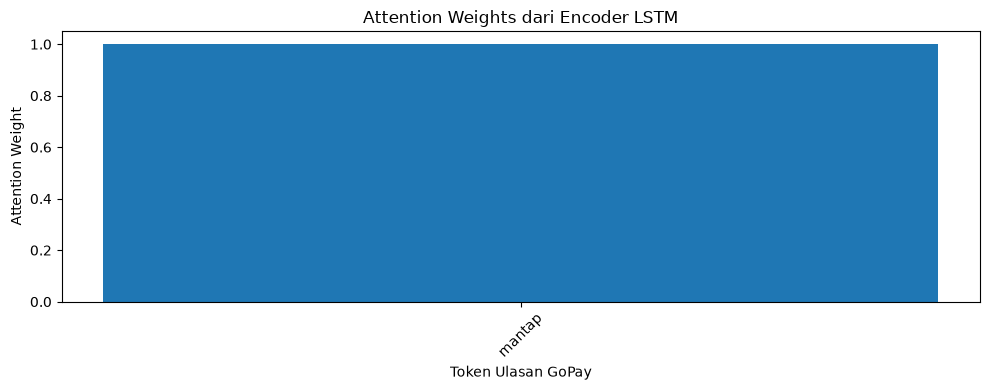

In [39]:
attention_values = weights.detach().numpy()

plt.figure(figsize=(10, 4))

plt.bar(tokens, attention_values[0])

plt.title("Attention Weights dari Encoder LSTM")
plt.xlabel("Token Ulasan GoPay")
plt.ylabel("Attention Weight")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# 10. Perbandingan: Tanpa Attention vs Dengan Attention

In [40]:
print("PERBANDINGAN TANPA ATTENTION DAN DENGAN ATTENTION")

print("\n1. Tanpa Attention:")
print("- Encoder menghasilkan representasi urutan.")
print("- Informasi dirangkum melalui hidden state.")
print("- Tidak ada bobot perhatian untuk setiap token.")

print("\n2. Dengan Attention:")
print("- Model menghitung bobot perhatian setiap token.")
print("- Model dapat memberikan fokus berbeda pada setiap token.")
print("- Context vector dibentuk berdasarkan attention weights.")

PERBANDINGAN TANPA ATTENTION DAN DENGAN ATTENTION

1. Tanpa Attention:
- Encoder menghasilkan representasi urutan.
- Informasi dirangkum melalui hidden state.
- Tidak ada bobot perhatian untuk setiap token.

2. Dengan Attention:
- Model menghitung bobot perhatian setiap token.
- Model dapat memberikan fokus berbeda pada setiap token.
- Context vector dibentuk berdasarkan attention weights.


# E. Tugas Analisis

**1. Ubah contoh kalimat pada demonstrasi self-attention. Apakah pola attention berubah?**

In [41]:
kalimat_baru = "aplikasi gopay sangat mudah digunakan dan membantu transaksi"

tokens, weights, output = self_attention(kalimat_baru)

print("Kalimat:", kalimat_baru)
print("\nToken:", tokens)
print("\nAttention Weights:")
print(weights)

Kalimat: aplikasi gopay sangat mudah digunakan dan membantu transaksi

Token: ['aplikasi', 'gopay', 'sangat', 'mudah', 'digunakan', 'dan', 'membantu', 'transaksi']

Attention Weights:
tensor([[2.5401e-06, 9.2856e-04, 9.5975e-01, 3.8642e-02, 3.4728e-04, 6.0555e-08,
         1.6717e-08, 3.2811e-04],
        [1.5848e-06, 2.3322e-01, 4.0140e-03, 6.7758e-03, 1.6420e-02, 5.6164e-01,
         3.2216e-05, 1.7789e-01],
        [1.2932e-11, 4.6865e-03, 9.7722e-01, 1.7454e-02, 1.4720e-06, 2.2391e-06,
         6.4138e-17, 6.3433e-04],
        [2.4404e-01, 1.1768e-02, 2.1619e-02, 3.0443e-06, 8.4962e-06, 6.7434e-01,
         9.2469e-05, 4.8125e-02],
        [4.7296e-06, 1.3873e-08, 2.1573e-12, 7.8183e-08, 2.1500e-06, 8.8361e-04,
         9.9911e-01, 3.0202e-09],
        [3.1858e-06, 1.9542e-01, 1.6562e-01, 7.7971e-05, 7.4534e-04, 7.9595e-03,
         1.1823e-06, 6.3017e-01],
        [5.5111e-05, 4.2160e-11, 1.1465e-13, 7.5115e-09, 2.9010e-08, 8.6093e-08,
         9.9994e-01, 3.0186e-11],
        [5.

Ya, pola attention dapat berubah ketika kalimat diganti. Hal ini karena setiap kalimat memiliki susunan kata dan konteks yang berbeda. Pada contoh ulasan GoPay, kata-kata yang digunakan juga berbeda sehingga hasil bobot attention yang ditampilkan dapat berubah.

**2. Buat skenario attention yang menunjukkan kata ambigu mendapat bobot berbeda dalam konteks berbeda.**

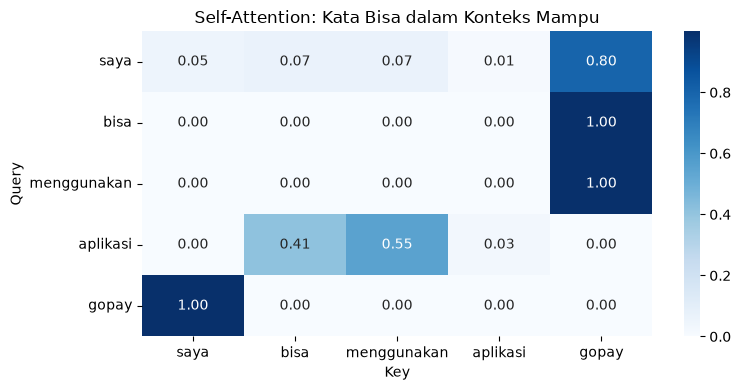

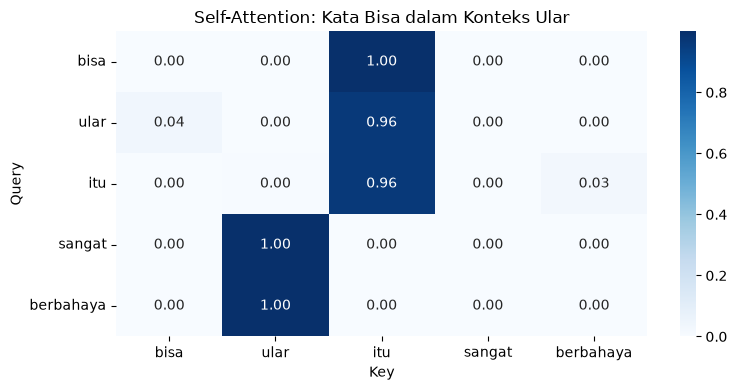

In [42]:
# Dua kalimat dengan kata ambigu "bisa"
kalimat_1 = "saya bisa menggunakan aplikasi gopay"
kalimat_2 = "bisa ular itu sangat berbahaya"

# Menghitung self-attention pada kedua kalimat
tokens_1, weights_1, output_1 = self_attention(kalimat_1)
tokens_2, weights_2, output_2 = self_attention(kalimat_2)

# Menampilkan visualisasi kalimat pertama
plt.figure(figsize=(8, 4))
sns.heatmap(
    weights_1.detach().numpy(),
    xticklabels=tokens_1,
    yticklabels=tokens_1,
    cmap="Blues",
    annot=True,
    fmt=".2f"
)
plt.title("Self-Attention: Kata Bisa dalam Konteks Mampu")
plt.xlabel("Key")
plt.ylabel("Query")
plt.tight_layout()
plt.show()

# Menampilkan visualisasi kalimat kedua
plt.figure(figsize=(8, 4))
sns.heatmap(
    weights_2.detach().numpy(),
    xticklabels=tokens_2,
    yticklabels=tokens_2,
    cmap="Blues",
    annot=True,
    fmt=".2f"
)
plt.title("Self-Attention: Kata Bisa dalam Konteks Ular")
plt.xlabel("Key")
plt.ylabel("Query")
plt.tight_layout()
plt.show()

Contoh kata ambigu adalah "bisa", yang dapat berarti mampu atau racun ular. Kode berikut membuat dua kalimat dengan kata yang sama, kemudian membandingkan bobot attention-nya.

**3. Visualisasikan attention untuk minimal 3 kalimat berbeda dari dataset.**

Kalimat 1: Bagus dan mudah digunakan


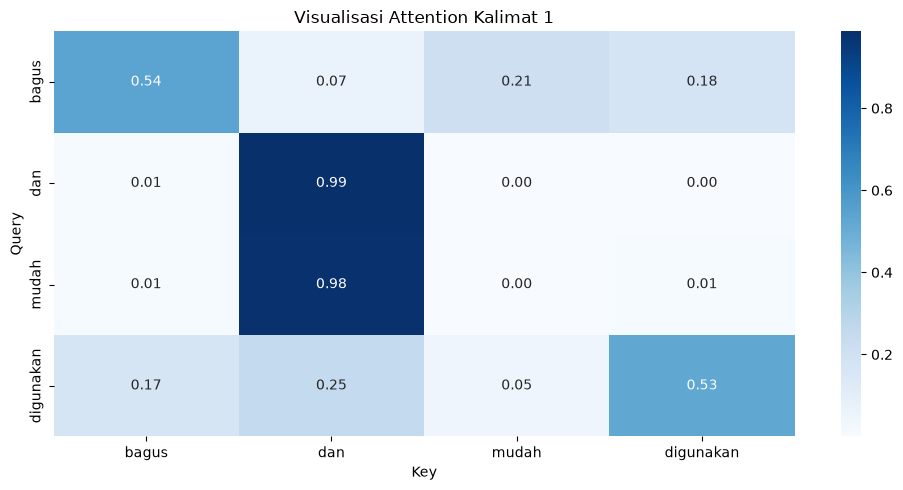

Kalimat 2: Sangat membantu orang menengah mantap semoga sukses terus gopay


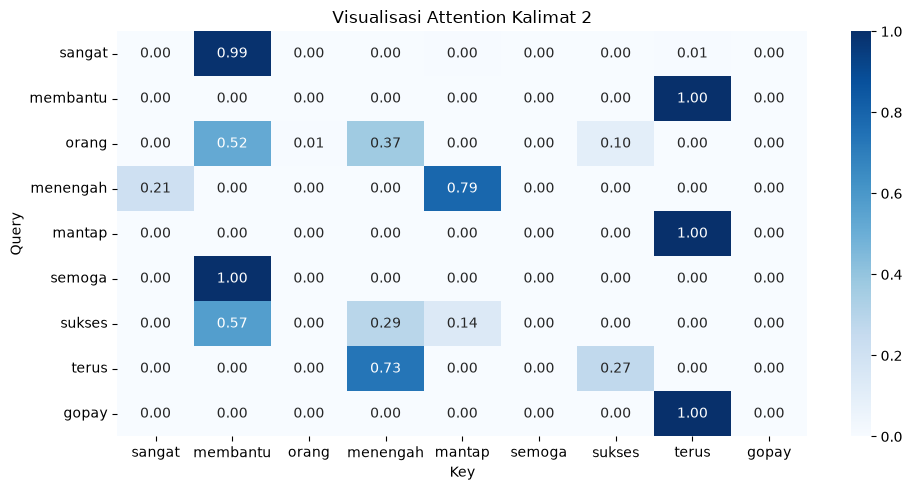

Kalimat 3: Ga ribet .. Sukaaaa


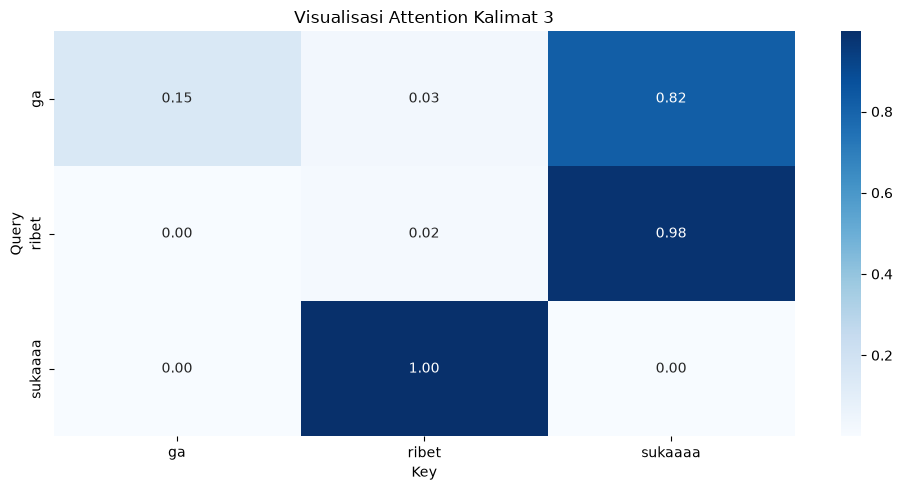

In [43]:
# Mengambil 3 kalimat berbeda dari dataset GoPay
reviews = df["content"].dropna().drop_duplicates()

selected_reviews = []

for review in reviews:
    review = str(review).strip()
    tokens = re.findall(r"\b\w+\b", review.lower())

    if len(tokens) >= 3:
        selected_reviews.append(review)

    if len(selected_reviews) == 3:
        break

# Menampilkan 3 kalimat dan visualisasi attention
for i, review in enumerate(selected_reviews, start=1):

    tokens = re.findall(r"\b\w+\b", review.lower())[:12]
    sentence = " ".join(tokens)

    tokens, weights, output = self_attention(sentence)

    print(f"Kalimat {i}: {review}")

    plt.figure(figsize=(10, 5))
    sns.heatmap(
        weights.detach().numpy(),
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        annot=True,
        fmt=".2f"
    )

    plt.title(f"Visualisasi Attention Kalimat {i}")
    plt.xlabel("Key")
    plt.ylabel("Query")
    plt.tight_layout()
    plt.show()

**4. Jelaskan dengan kata-kata sendiri: mengapa attention mengatasi bottleneck problem?**

Menurut saya, attention membuat model lebih mudah memahami isi kalimat karena model bisa fokus pada kata-kata yang penting. Jadi, informasi tidak hanya disimpan dalam satu rangkuman, tetapi model bisa melihat kembali kata yang dibutuhkan agar tidak ada informasi penting yang terlewat.

**5. Berikan analogi sederhana untuk menjelaskan konsep Query, Key, Value kepada orang awam.**

Analogi sederhananya seperti mencari makanan di restoran.
- Query: Kita menyampaikan makanan yang ingin dicari, misalnya nasi goreng.
- Key: Nama atau daftar menu yang diperiksa untuk menemukan makanan yang sesuai.
- Value: Informasi atau isi dari menu yang kita pilih.

Jadi, Query adalah apa yang kita cari, Key adalah petunjuk untuk mencocokkan, dan Value adalah informasi yang kita dapatkan.


## F. Pertanyaan Diskusi

**1. Apa perbedaan antara Bahdanau Attention dan Scaled Dot-Product Attention?**

Menurut saya, perbedaannya ada pada cara menghitung perhatian. Bahdanau Attention menggunakan jaringan sederhana untuk menghitung hubungan antara query dan key, sedangkan Scaled Dot-Product Attention menghitung kecocokan dengan perkalian matriks, kemudian hasilnya dibagi dengan akar dimensi key agar nilainya lebih stabil.

**2. Mengapa self-attention lebih baik dari recurrent connection untuk menangkap konteks jangka panjang?**

Karena self-attention bisa melihat hubungan antar kata dalam satu kalimat secara langsung, meskipun jarak katanya jauh. Sedangkan recurrent connection memproses kata satu per satu sehingga hubungan antar kata yang berjauhan lebih sulit ditangkap.

**3. Apa yang dimaksud dengan multi-head attention? Mengapa menggunakan beberapa head?**

Multi-head attention adalah teknik yang menggunakan beberapa attention secara bersamaan. Tujuannya agar model bisa memperhatikan berbagai hubungan antar kata dari sudut pandang yang berbeda, sehingga informasi yang didapat lebih lengkap.

**4. Mengapa Transformer (yang menggunakan self-attention) dapat diparalelkan, sedangkan RNN tidak?**

Karena Transformer dapat memproses hubungan antar kata secara bersamaan, sedangkan RNN harus membaca kata secara berurutan dari awal sampai akhir. Oleh karena itu, Transformer bisa memanfaatkan pemrosesan secara paralel dan lebih cepat dalam banyak kondisi.

**5. Bagaimana attention weights dapat digunakan untuk interpretabilitas model NLP?**

Attention weights dapat membantu kita melihat kata mana yang lebih diperhatikan oleh model ketika memproses sebuah kalimat. Dari bobot tersebut, kita bisa mengetahui bagian teks yang dianggap penting oleh model dalam menghasilkan suatu output.